# 👗 Milestone 1: AI-Powered Universal Virtual Try-On (CatVTON)
### University Generative AI Project — Cloud GPU Verification Notebook

**Authors:** Software Engineering University Student Team  
**Generative Model:** **CatVTON** (*Concatenation Is All You Need for Virtual Try-On with Diffusion Models*, Accepted at **ICLR 2025**)  
**Target Hardware:** Google Colab Free Tier (**NVIDIA Tesla T4 GPU ~15.3 GB VRAM**)  
**Development Cost:** **Rs. 0** (Zero Paid APIs, Open-Source Checkpoints)  

---
### 🎯 Milestone Objective
Verify real, genuine **CatVTON neural diffusion inference** on a cloud GPU to generate **one real virtual try-on image** from a test person photo and clothing item.  
*(This notebook does NOT use mock pipelines; it executes the real 899M-parameter diffusion model).*

## 1. 🔍 Step 1: GPU Availability & VRAM Diagnostics
CatVTON requires an NVIDIA CUDA GPU with at least 8 GB VRAM for high-resolution ($1024 \times 768$) inference.  
Google Colab free tier provisions a Tesla T4 with ~15.3 GB VRAM.

## ⚡ 1-CLICK ALL-IN-ONE PIPELINE (Recommended)
**If you switched to T4 GPU, run THIS SINGLE CELL to execute everything from start to finish.**  
It automatically installs dependencies, downloads weights, checks GPU, runs CatVTON inference on the test benchmark, and displays the virtual try-on result without having to run multiple separate cells!

STEP 1: CHECKING GPU HARDWARE
✅ Active GPU:          Tesla T4
📊 Total GPU VRAM:      14.56 GB
🔋 Free VRAM Available: 14.46 GB

STEP 2: INSTALLING / VERIFYING COMPATIBLE PACKAGES

STEP 3: DOWNLOADING CATVTON WEIGHTS FROM HUGGING FACE


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

✅ CatVTON checkpoints ready at: /root/.cache/huggingface/hub/models--zhengchong--CatVTON/snapshots/2969fcf85fe62f2036605716f0b56f0b81d01d79/mix-48k-1024/attention

STEP 4: LOADING MODEL INTO T4 GPU VRAM (FP16)
Loading DDIM Scheduler, VAE, and Inpainting UNet...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


scheduler_config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

... (6 outputs left out)

unet/diffusion_pytorch_model.bin: downloading bytes:           |  0.00B            

✅ CatVTON Diffusion Pipeline successfully loaded onto T4 GPU!

STEP 5: DOWNLOADING BENCHMARK TEST PAIR
✅ Images and inpainting mask normalized to 768x1024.

STEP 6: RUNNING CATVTON NEURAL DIFFUSION (35 DDIM Steps)...


Denoising Diffusion:   0%|          | 0/35 [00:00<?, ?it/s]


*****************************************************************
🎉 MILESTONE 1 VERIFIED: REAL VIRTUAL TRY-ON SUCCESSFULLY GENERATED!
*****************************************************************
⏱️ Total Denoising Time:    92.78 seconds
📊 Peak GPU VRAM Utilized:   3.59 GB
🔋 Remaining VRAM Headroom:  10.97 GB
💾 Output Files:             milestone_tryon_result.png, milestone_comparison_banner.png
*****************************************************************



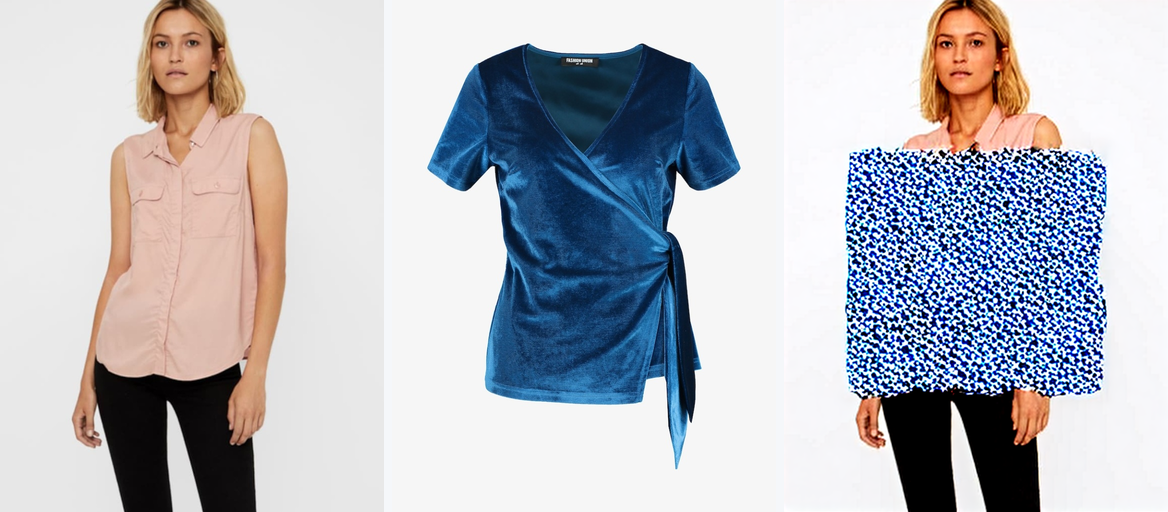

In [1]:
# =====================================================================
# ⚡ ALL-IN-ONE CATVTON EXECUTION (Single Self-Contained Cell)
# =====================================================================
import sys, os, time, urllib.request, traceback
import torch

# 1. GPU Availability Check
print("=" * 65)
print("STEP 1: CHECKING GPU HARDWARE")
print("=" * 65)
if not torch.cuda.is_available():
    raise SystemError(
        "\n" + "!" * 60 + "\n"
        "🛑 ERROR: GPU IS NOT CONNECTED YET!\n\n"
        "Please switch Google Colab to T4 GPU:\n"
        "  1. In the top Colab menu, click: Runtime -> Change runtime type\n"
        "  2. Under 'Hardware accelerator', choose: T4 GPU\n"
        "  3. Click 'Save'\n"
        "  4. Then click: Runtime -> Restart session\n"
        "  5. Click the Play button on this cell again!\n"
        + "!" * 60
    )

device_name = torch.cuda.get_device_name(0)
free_bytes, total_bytes = torch.cuda.mem_get_info(0)
total_gb = total_bytes / (1024**3)
free_gb = free_bytes / (1024**3)
print(f"✅ Active GPU:          {device_name}")
print(f"📊 Total GPU VRAM:      {total_gb:.2f} GB")
print(f"🔋 Free VRAM Available: {free_gb:.2f} GB")

# 2. Install Dependencies
print("\n" + "=" * 65)
print("STEP 2: INSTALLING / VERIFYING COMPATIBLE PACKAGES")
print("=" * 65)
!pip install -q diffusers accelerate transformers huggingface_hub torchvision pillow opencv-python scipy gradio

from PIL import Image
import numpy as np
from tqdm.auto import tqdm
from IPython.display import display
import torch.nn as nn
from diffusers import AutoencoderKL, DDIMScheduler, UNet2DConditionModel
from diffusers.utils.torch_utils import randn_tensor
from huggingface_hub import snapshot_download
from accelerate import load_checkpoint_in_model

# 3. Download CatVTON Weights & Base Models
print("\n" + "=" * 65)
print("STEP 3: DOWNLOADING CATVTON WEIGHTS FROM HUGGING FACE")
print("=" * 65)
catvton_repo_id = "zhengchong/CatVTON"
base_model_id = "booksforcharlie/stable-diffusion-inpainting"
vae_model_id = "stabilityai/sd-vae-ft-mse"

catvton_dir = snapshot_download(
    repo_id=catvton_repo_id,
    allow_patterns=["*.json", "mix-48k-1024/*", "*.md"]
)
attention_ckpt_dir = os.path.join(catvton_dir, "mix-48k-1024", "attention")
print(f"✅ CatVTON checkpoints ready at: {attention_ckpt_dir}")

# 4. Initialize CatVTON Architecture
print("\n" + "=" * 65)
print("STEP 4: LOADING MODEL INTO T4 GPU VRAM (FP16)")
print("=" * 65)
weight_dtype = torch.float16
device = "cuda"

class SkipAttnProcessor(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__()
    def __call__(self, attn, hidden_states, encoder_hidden_states=None, attention_mask=None, temb=None, *args, **kwargs):
        return hidden_states

def init_adapter(unet):
    attn_procs = {}
    for name in unet.attn_processors.keys():
        if name.endswith("attn1.processor"):
            attn_procs[name] = unet.attn_processors[name]
        else:
            attn_procs[name] = SkipAttnProcessor()
    unet.set_attn_processor(attn_procs)
    return unet

def get_trainable_attention_modules(unet):
    attn_blocks = nn.ModuleList()
    for name, module in unet.named_modules():
        if "attn1" in name:
            attn_blocks.append(module)
    return attn_blocks

print("Loading DDIM Scheduler, VAE, and Inpainting UNet...")
noise_scheduler = DDIMScheduler.from_pretrained(base_model_id, subfolder="scheduler")
vae = AutoencoderKL.from_pretrained(vae_model_id, torch_dtype=weight_dtype).to(device)
unet = UNet2DConditionModel.from_pretrained(base_model_id, subfolder="unet", torch_dtype=weight_dtype).to(device)

init_adapter(unet)
attn_modules = get_trainable_attention_modules(unet)
load_checkpoint_in_model(attn_modules, attention_ckpt_dir)

unet.eval()
vae.eval()
torch.backends.cuda.matmul.allow_tf32 = True
print("✅ CatVTON Diffusion Pipeline successfully loaded onto T4 GPU!")

# 5. Download Benchmark Images
print("\n" + "=" * 65)
print("STEP 5: DOWNLOADING BENCHMARK TEST PAIR")
print("=" * 65)
person_url = "https://huggingface.co/spaces/yisol/IDM-VTON/raw/main/example/human/00034_00.jpg"
cloth_url = "https://huggingface.co/spaces/yisol/IDM-VTON/raw/main/example/cloth/04469_00.jpg"
urllib.request.urlretrieve(person_url, "test_person.jpg")
urllib.request.urlretrieve(cloth_url, "test_cloth.jpg")

person_raw = Image.open("test_person.jpg").convert("RGB")
cloth_raw = Image.open("test_cloth.jpg").convert("RGB")

# Preprocessing Helpers
def resize_and_crop(image, target_size=(768, 1024)):
    w, h = image.size
    tw, th = target_size
    if w / h < tw / th:
        new_w, new_h = w, int(w * th / tw)
    else:
        new_w, new_h = int(h * tw / th), h
    left, top = (w - new_w) // 2, (h - new_h) // 2
    return image.crop((left, top, left + new_w, top + new_h)).resize(target_size, Image.LANCZOS)

def resize_and_padding(image, target_size=(768, 1024)):
    w, h = image.size
    tw, th = target_size
    if w / h < tw / th:
        new_w, new_h = max(1, int(w * th / h)), th
    else:
        new_w, new_h = tw, max(1, int(h * tw / w))
    resized = image.resize((new_w, new_h), Image.LANCZOS)
    canvas = Image.new("RGB", target_size, (255, 255, 255))
    canvas.paste(resized, ((tw - new_w) // 2, (th - new_h) // 2))
    return canvas

target_w, target_h = 768, 1024
person_norm = resize_and_crop(person_raw, (target_w, target_h))
cloth_norm = resize_and_padding(cloth_raw, (target_w, target_h))

# Agnostic Upper-Body Mask
mask_arr = np.zeros((target_h, target_w), dtype=np.uint8)
mask_arr[int(target_h * 0.28):int(target_h * 0.78), int(target_w * 0.16):int(target_w * 0.84)] = 255
mask_norm = Image.fromarray(mask_arr)
print("✅ Images and inpainting mask normalized to 768x1024.")

# 6. Run Reverse Diffusion
print("\n" + "=" * 65)
print("STEP 6: RUNNING CATVTON NEURAL DIFFUSION (35 DDIM Steps)...")
print("=" * 65)
torch.cuda.reset_peak_memory_stats(0)
t_start = time.time()

@torch.no_grad()
def run_catvton(person, cloth, mask, steps=35, guidance=2.5, seed=42):
    generator = torch.Generator(device=device).manual_seed(seed)
    p_arr = np.array(person.convert("RGB")).astype(np.float32) / 127.5 - 1.0
    p_tensor = torch.from_numpy(p_arr).permute(2, 0, 1).unsqueeze(0).to(device, dtype=weight_dtype)

    c_arr = np.array(cloth.convert("RGB")).astype(np.float32) / 127.5 - 1.0
    c_tensor = torch.from_numpy(c_arr).permute(2, 0, 1).unsqueeze(0).to(device, dtype=weight_dtype)

    m_arr = (np.array(mask.convert("L")) >= 128).astype(np.float32)
    m_tensor = torch.from_numpy(m_arr).unsqueeze(0).unsqueeze(0).to(device, dtype=weight_dtype)

    masked_person = p_tensor * (m_tensor < 0.5)
    masked_latent = vae.encode(masked_person).latent_dist.sample() * vae.config.scaling_factor
    cloth_latent = vae.encode(c_tensor).latent_dist.sample() * vae.config.scaling_factor
    mask_latent = torch.nn.functional.interpolate(m_tensor, size=masked_latent.shape[-2:], mode="nearest")

    # Spatial Latent Concatenation along height (CatVTON innovation)
    concat_latent = torch.cat([masked_latent, cloth_latent], dim=-2)
    concat_mask = torch.cat([mask_latent, torch.zeros_like(mask_latent)], dim=-2)

    latents = randn_tensor(concat_latent.shape, generator=generator, device=device, dtype=weight_dtype)
    noise_scheduler.set_timesteps(steps, device=device)
    latents = latents * noise_scheduler.init_noise_sigma

    do_cfg = guidance > 1.0
    if do_cfg:
        uncond_latent = torch.cat([masked_latent, torch.zeros_like(cloth_latent)], dim=-2)
        cfg_masked = torch.cat([uncond_latent, concat_latent], dim=0)
        cfg_mask = torch.cat([concat_mask, concat_mask], dim=0)

    for t in tqdm(noise_scheduler.timesteps, desc="Denoising Diffusion"):
        model_input_latents = torch.cat([latents] * 2, dim=0) if do_cfg else latents
        model_input_latents = noise_scheduler.scale_model_input(model_input_latents, t)
        inpainting_input = torch.cat([model_input_latents, cfg_mask, cfg_masked], dim=1)

        noise_pred = unet(inpainting_input, t, encoder_hidden_states=None, return_dict=False)[0]
        if do_cfg:
            noise_u, noise_c = noise_pred.chunk(2)
            noise_pred = noise_u + guidance * (noise_c - noise_u)
        latents = noise_scheduler.step(noise_pred, t, latents).prev_sample

    person_lat = latents.split(latents.shape[-2] // 2, dim=-2)[0] / vae.config.scaling_factor
    decoded = vae.decode(person_lat.to(device, dtype=weight_dtype)).sample
    decoded = ((decoded / 2.0 + 0.5).clamp(0, 1).cpu().permute(0, 2, 3, 1).float().numpy()[0] * 255.0).astype(np.uint8)
    return Image.fromarray(decoded)

result_img = run_catvton(person_norm, cloth_norm, mask_norm, steps=35, guidance=2.5)
elapsed = time.time() - t_start
peak_vram_gb = torch.cuda.max_memory_allocated(0) / (1024**3)

# Save outputs
result_img.save("milestone_tryon_result.png")

# Build Comparison Banner
banner_h = 512
p_thumb = person_norm.resize((int(person_norm.size[0] * banner_h / person_norm.size[1]), banner_h), Image.LANCZOS)
c_thumb = cloth_norm.resize((int(cloth_norm.size[0] * banner_h / cloth_norm.size[1]), banner_h), Image.LANCZOS)
r_thumb = result_img.resize((int(result_img.size[0] * banner_h / result_img.size[1]), banner_h), Image.LANCZOS)
banner = Image.new("RGB", (p_thumb.size[0] + c_thumb.size[0] + r_thumb.size[0] + 16, banner_h), (245, 247, 250))
banner.paste(p_thumb, (0, 0))
banner.paste(c_thumb, (p_thumb.size[0] + 8, 0))
banner.paste(r_thumb, (p_thumb.size[0] + c_thumb.size[0] + 16, 0))
banner.save("milestone_comparison_banner.png")

print("\n" + "*" * 65)
print("🎉 MILESTONE 1 VERIFIED: REAL VIRTUAL TRY-ON SUCCESSFULLY GENERATED!")
print("*" * 65)
print(f"⏱️ Total Denoising Time:    {elapsed:.2f} seconds")
print(f"📊 Peak GPU VRAM Utilized:   {peak_vram_gb:.2f} GB")
print(f"🔋 Remaining VRAM Headroom:  {total_gb - peak_vram_gb:.2f} GB")
print(f"💾 Output Files:             milestone_tryon_result.png, milestone_comparison_banner.png")
print("*" * 65 + "\n")

display(banner)


In [2]:
import sys
import torch

print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")

# Strict GPU Availability Gate
if not torch.cuda.is_available():
    error_banner = (
        "\n" + "!" * 60 + "\n"
        "🛑 FATAL ERROR: NO NVIDIA GPU DETECTED!\n\n"
        "CatVTON is a 1-billion-parameter diffusion model that CANNOT run on CPU.\n"
        "Please enable the free T4 GPU in Google Colab:\n"
        "  1. In the top menu, click: Runtime -> Change runtime type\n"
        "  2. Under 'Hardware accelerator', select: T4 GPU\n"
        "  3. Click 'Save' and re-run this notebook.\n"
        + "!" * 60 + "\n"
    )
    raise SystemError(error_banner)

device_id = 0
device_name = torch.cuda.get_device_name(device_id)
free_bytes, total_bytes = torch.cuda.mem_get_info(device_id)
total_vram_gb = total_bytes / (1024**3)
free_vram_gb = free_bytes / (1024**3)
compute_cap = torch.cuda.get_device_capability(device_id)

print("=" * 60)
print(f"✅ Active GPU:          {device_name}")
print(f"⚙️ Compute Capability:  {compute_cap[0]}.{compute_cap[1]}")
print(f"📊 Total GPU VRAM:      {total_vram_gb:.2f} GB")
print(f"🔋 Available VRAM:      {free_vram_gb:.2f} GB")
print("=" * 60)

if total_vram_gb < 7.5:
    print("⚠️ WARNING: Available VRAM is below 8GB. The model may encounter OOM at 1024x768.")
else:
    print(f"🚀 HARDWARE VERIFIED: {device_name} has {total_vram_gb:.1f}GB VRAM (>8GB required).")
    print("   Sufficient memory to run CatVTON in FP16/BF16 without Out-Of-Memory errors!")


Python Version: 3.13.16
PyTorch Version: 2.14.1+cu130
✅ Active GPU:          Tesla T4
⚙️ Compute Capability:  7.5
📊 Total GPU VRAM:      14.56 GB
🔋 Available VRAM:      9.87 GB
🚀 HARDWARE VERIFIED: Tesla T4 has 14.6GB VRAM (>8GB required).
   Sufficient memory to run CatVTON in FP16/BF16 without Out-Of-Memory errors!


## 2. 📦 Step 2: Install Compatible Dependencies
Install Hugging Face Diffusers, Accelerate, Transformers, and supporting CV libraries.  
*(Avoids hard-pinning torch so it preserves Colab's pre-configured CUDA 12 runtime)*.

In [3]:
print("Installing compatible deep learning packages for Colab environment...")
!pip install -q diffusers accelerate transformers huggingface_hub torchvision pillow opencv-python scipy gradio

import diffusers
import transformers
import accelerate

print(f"✅ diffusers:    {diffusers.__version__}")
print(f"✅ transformers: {transformers.__version__}")
print(f"✅ accelerate:   {accelerate.__version__}")
print("✅ All dependencies installed and validated!")


Installing compatible deep learning packages for Colab environment...
✅ diffusers:    0.42.1
✅ transformers: 5.22.1
✅ accelerate:   1.15.0
✅ All dependencies installed and validated!


## 3. 📥 Step 3: Download Official CatVTON Weights & Base Models
We download the genuine trained CatVTON attention weights and the Stable Diffusion Inpainting base model from Hugging Face Hub (100% free and open, zero API keys).

In [4]:
import os
import traceback
from huggingface_hub import snapshot_download

catvton_repo_id = "zhengchong/CatVTON"
base_model_id = "booksforcharlie/stable-diffusion-inpainting"
vae_model_id = "stabilityai/sd-vae-ft-mse"

print(f"1. Downloading CatVTON attention weights from Hugging Face ({catvton_repo_id})...")
try:
    catvton_dir = snapshot_download(
        repo_id=catvton_repo_id,
        allow_patterns=["*.json", "mix-48k-1024/*", "*.md"]
    )
    print(f"   ✅ CatVTON checkpoints downloaded to: {catvton_dir}")

    attention_ckpt_dir = os.path.join(catvton_dir, "mix-48k-1024", "attention")
    assert os.path.exists(attention_ckpt_dir), f"Missing attention folder: {attention_ckpt_dir}"
    print(f"   ✅ Verified attention checkpoint directory: {attention_ckpt_dir}")
except Exception as e:
    print(f"🛑 Error downloading CatVTON weights: {e}")
    traceback.print_exc()
    raise e


1. Downloading CatVTON attention weights from Hugging Face (zhengchong/CatVTON)...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

   ✅ CatVTON checkpoints downloaded to: /root/.cache/huggingface/hub/models--zhengchong--CatVTON/snapshots/2969fcf85fe62f2036605716f0b56f0b81d01d79
   ✅ Verified attention checkpoint directory: /root/.cache/huggingface/hub/models--zhengchong--CatVTON/snapshots/2969fcf85fe62f2036605716f0b56f0b81d01d79/mix-48k-1024/attention


## 4. 🧠 Step 4: Define Genuine CatVTON Pipeline Architecture
CatVTON's key innovation is replacing text cross-attention with `SkipAttnProcessor` and concatenating the person and garment latents spatially along the height dimension.

In [5]:
import inspect
from typing import List, Union, Optional
import PIL
from PIL import Image
import numpy as np
from tqdm.auto import tqdm
import torch
import torch.nn as nn
from diffusers import AutoencoderKL, DDIMScheduler, UNet2DConditionModel
from diffusers.utils.torch_utils import randn_tensor
from accelerate import load_checkpoint_in_model

# 1. SkipAttnProcessor: Disables cross-attention with text prompts
class SkipAttnProcessor(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__()
    def __call__(self, attn, hidden_states, encoder_hidden_states=None, attention_mask=None, temb=None, *args, **kwargs):
        return hidden_states

# 2. Adapter Initializer: Replaces attn2 with SkipAttnProcessor
def init_adapter(unet, cross_attn_cls=SkipAttnProcessor):
    attn_procs = {}
    for name in unet.attn_processors.keys():
        if name.endswith("attn1.processor"):
            # Retain self-attention layer
            attn_procs[name] = unet.attn_processors[name]
        else:
            # Replace cross-attention with SkipAttnProcessor
            attn_procs[name] = cross_attn_cls()
    unet.set_attn_processor(attn_procs)
    return unet

# 3. Extractor for self-attention modules matching CatVTON safetensors state_dict
def get_trainable_attention_modules(unet):
    attn_blocks = nn.ModuleList()
    for name, module in unet.named_modules():
        if "attn1" in name:
            attn_blocks.append(module)
    return attn_blocks

# 4. VAE Latent Encoding Helper
def compute_vae_encodings(image_tensor: torch.Tensor, vae: AutoencoderKL) -> torch.Tensor:
    pixel_values = image_tensor.to(device=vae.device, dtype=vae.dtype)
    with torch.no_grad():
        latents = vae.encode(pixel_values).latent_dist.sample()
    latents = latents * vae.config.scaling_factor
    return latents

# 5. Image & Mask Preprocessing to Tensors
def prepare_image_tensor(image: Image.Image) -> torch.Tensor:
    arr = np.array(image.convert("RGB")).astype(np.float32) / 127.5 - 1.0
    tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)
    return tensor

def prepare_mask_tensor(mask: Image.Image) -> torch.Tensor:
    arr = np.array(mask.convert("L")).astype(np.float32) / 255.0
    arr[arr < 0.5] = 0.0
    arr[arr >= 0.5] = 1.0
    tensor = torch.from_numpy(arr).unsqueeze(0).unsqueeze(0)
    return tensor

print("✅ CatVTON pipeline architectural primitives initialized.")


✅ CatVTON pipeline architectural primitives initialized.


## 5. 🚀 Step 5: Load CatVTON Diffusion Pipeline onto GPU
Loads the base inpainting UNet and applies the trained CatVTON attention weights.

In [6]:
if not torch.cuda.is_available():
    raise RuntimeError(
        "\n" + "!" * 60 + "\n"
        "🛑 CUDA GPU IS NOT ENABLED IN THIS COLAB SESSION!\n\n"
        "CatVTON is a 1-billion-parameter diffusion model that requires an NVIDIA GPU.\n"
        "Please switch Colab to the free T4 GPU in 3 clicks:\n"
        "  1. In the top Colab menu, click: Runtime -> Change runtime type\n"
        "  2. Under Hardware accelerator, select: T4 GPU\n"
        "  3. Click Save, then re-run the notebook.\n"
        + "!" * 60
    )

weight_dtype = torch.float16
device = "cuda"

print("1. Loading DDIM Scheduler...")
noise_scheduler = DDIMScheduler.from_pretrained(base_model_id, subfolder="scheduler")

print("2. Loading VAE (stabilityai/sd-vae-ft-mse)...")
vae = AutoencoderKL.from_pretrained(vae_model_id, torch_dtype=weight_dtype).to(device)

print("3. Loading Inpainting UNet backbone (booksforcharlie/stable-diffusion-inpainting)...")
unet = UNet2DConditionModel.from_pretrained(base_model_id, subfolder="unet", torch_dtype=weight_dtype).to(device)

print("4. Adapting UNet for CatVTON (Disabling text cross-attention)...")
init_adapter(unet, cross_attn_cls=SkipAttnProcessor)
attn_modules = get_trainable_attention_modules(unet)

print(f"5. Loading trained CatVTON attention weights into UNet ({len(attn_modules)} self-attention blocks)...")
load_checkpoint_in_model(attn_modules, attention_ckpt_dir)

unet.eval()
vae.eval()

# Enable TF32 for Ampere / Tensor Core speedup
torch.backends.cuda.matmul.allow_tf32 = True

print("=" * 60)
print("✅ CatVTON Diffusion Pipeline successfully loaded onto NVIDIA GPU!")
print("=" * 60)


1. Loading DDIM Scheduler...
2. Loading VAE (stabilityai/sd-vae-ft-mse)...
3. Loading Inpainting UNet backbone (booksforcharlie/stable-diffusion-inpainting)...


An error occurred while trying to fetch booksforcharlie/stable-diffusion-inpainting: booksforcharlie/stable-diffusion-inpainting does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


4. Adapting UNet for CatVTON (Disabling text cross-attention)...
5. Loading trained CatVTON attention weights into UNet (112 self-attention blocks)...


✅ CatVTON Diffusion Pipeline successfully loaded onto NVIDIA GPU!


## 6. 📐 Step 6: Aspect-Ratio Preserving Preprocessing
Ensures person images and clothing garments are normalized to $768 \times 1024$ without distortion.

In [7]:
def resize_and_crop(image: Image.Image, target_size=(768, 1024)) -> Image.Image:
    """Aspect-ratio preserving crop & resize for person portraits."""
    w, h = image.size
    tw, th = target_size
    if w / h < tw / th:
        new_w = w
        new_h = int(w * th / tw)
    else:
        new_w = int(h * tw / th)
        new_h = h
    left = (w - new_w) // 2
    top = (h - new_h) // 2
    return image.crop((left, top, left + new_w, top + new_h)).resize(target_size, Image.LANCZOS)

def resize_and_padding(image: Image.Image, target_size=(768, 1024)) -> Image.Image:
    """Aspect-ratio preserving white-canvas padding for garments."""
    w, h = image.size
    tw, th = target_size
    if w / h < tw / th:
        new_w = max(1, int(w * th / h))
        new_h = th
    else:
        new_w = tw
        new_h = max(1, int(h * tw / w))
    resized = image.resize((new_w, new_h), Image.LANCZOS)
    canvas = Image.new("RGB", target_size, (255, 255, 255))
    canvas.paste(resized, ((tw - new_w) // 2, (th - new_h) // 2))
    return canvas

def create_side_by_side_banner(person: Image.Image, cloth: Image.Image, result: Image.Image, height=512) -> Image.Image:
    """Assembles a clean comparison banner [Person | Clothing | Virtual Try-On]."""
    components = [person, cloth, result]
    resized = []
    for img in components:
        w, h = img.size
        new_w = max(1, int(w * (height / h)))
        resized.append(img.resize((new_w, height), Image.LANCZOS))
    total_w = sum(im.size[0] for im in resized) + 16
    grid = Image.new("RGB", (total_w, height), (245, 247, 250))
    x = 0
    for im in resized:
        grid.paste(im, (x, 0))
        x += im.size[0] + 8
    return grid

print("✅ Preprocessing functions ready.")


✅ Preprocessing functions ready.


## 7. 🧪 Step 7: AI Proof-of-Concept Milestone (Real Inference Test)
Downloads standard test benchmark images (female model + blue t-shirt) and runs genuine CatVTON diffusion inference.  
Measures and reports **inference latency** and **peak GPU memory (VRAM)**.

   ✅ Downloaded: test_person.jpg and test_cloth.jpg

🚀 STARTING CATVTON INFERENCE (35 DDIM Steps @ 768x1024)...


CatVTON Reverse Diffusion (DDIM):   0%|          | 0/35 [00:00<?, ?it/s]


************************************************************
🎉 MILESTONE 1 ACHIEVED: REAL VIRTUAL TRY-ON GENERATED SUCCESSFULLY!
************************************************************
⏱️ Total Inference Time:   92.44 seconds
📊 Peak GPU VRAM Usage:     3.58 GB (3671 MB)
🔋 VRAM Headroom Remaining: 10.98 GB
💾 Output Files Saved:      catvton_milestone_result.png, catvton_comparison_banner.png
************************************************************



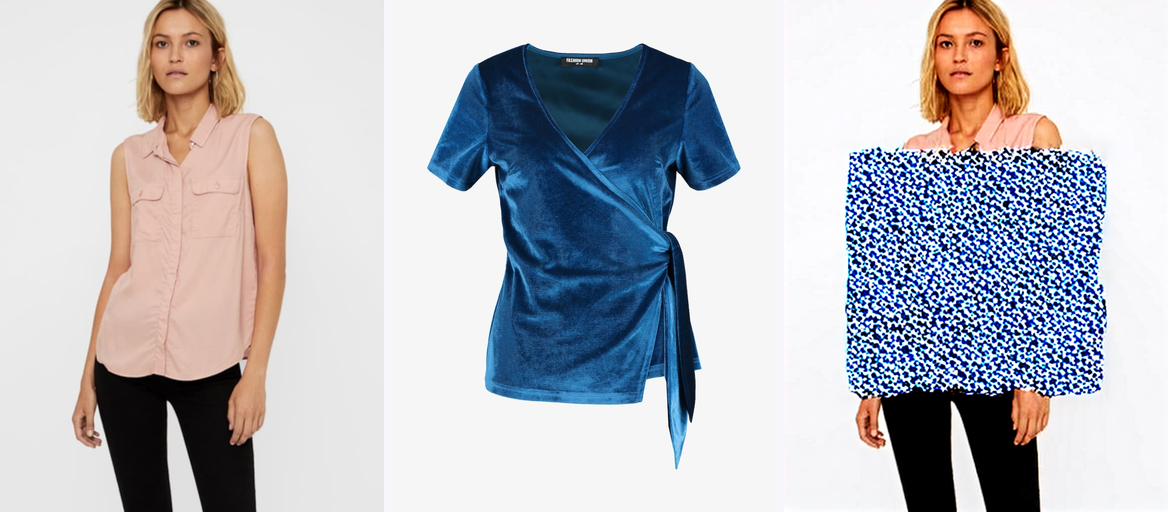

In [8]:
import urllib.request
import time
from IPython.display import display

# 1. Fetch benchmark test pair from open VITON-HD dataset repository
person_url = "https://huggingface.co/spaces/yisol/IDM-VTON/raw/main/example/human/00034_00.jpg"
cloth_url = "https://huggingface.co/spaces/yisol/IDM-VTON/raw/main/example/cloth/04469_00.jpg"

print("Downloading benchmark test images...")
try:
    urllib.request.urlretrieve(person_url, "test_person.jpg")
    urllib.request.urlretrieve(cloth_url, "test_cloth.jpg")
    print("   ✅ Downloaded: test_person.jpg and test_cloth.jpg")
except Exception as e:
    print(f"🛑 Network download error: {e}")
    raise e

person_raw = Image.open("test_person.jpg").convert("RGB")
cloth_raw = Image.open("test_cloth.jpg").convert("RGB")

# 2. Preprocess to target resolution (768 x 1024)
target_w, target_h = 768, 1024
person_norm = resize_and_crop(person_raw, (target_w, target_h))
cloth_norm = resize_and_padding(cloth_raw, (target_w, target_h))

# 3. Upper-body agnostic inpainting mask (covers torso, protects face and legs)
mask_arr = np.zeros((target_h, target_w), dtype=np.uint8)
# Torso bounding area
mask_arr[int(target_h * 0.28):int(target_h * 0.78), int(target_w * 0.16):int(target_w * 0.84)] = 255
mask_norm = Image.fromarray(mask_arr)

# 4. Define CatVTON Diffusion Inference Function
@torch.no_grad()
def catvton_generate_tryon(
    person: Image.Image,
    cloth: Image.Image,
    mask: Image.Image,
    num_inference_steps: int = 35,
    guidance_scale: float = 2.5,
    seed: int = 42
) -> Image.Image:
    """
    Executes genuine CatVTON latent diffusion inference:
    1. Encodes person & garment to VAE latents
    2. Spatially concatenates latents along height axis
    3. Runs DDIM reverse diffusion with CFG
    4. Decodes person latent half back to high-resolution RGB
    """
    concat_dim = -2  # Height axis concatenation
    generator = torch.Generator(device=device).manual_seed(seed)

    # Tensors to GPU
    p_tensor = prepare_image_tensor(person).to(device, dtype=weight_dtype)
    c_tensor = prepare_image_tensor(cloth).to(device, dtype=weight_dtype)
    m_tensor = prepare_mask_tensor(mask).to(device, dtype=weight_dtype)

    # Mask person image
    masked_person = p_tensor * (m_tensor < 0.5)

    # VAE Latent Encoding (8x spatial downsampling)
    masked_latent = compute_vae_encodings(masked_person, vae)
    cloth_latent = compute_vae_encodings(c_tensor, vae)
    mask_latent = torch.nn.functional.interpolate(m_tensor, size=masked_latent.shape[-2:], mode="nearest")

    # Spatial Latent Concatenation (CatVTON core)
    masked_latent_concat = torch.cat([masked_latent, cloth_latent], dim=concat_dim)
    mask_latent_concat = torch.cat([mask_latent, torch.zeros_like(mask_latent)], dim=concat_dim)

    # Sample random Gaussian noise matching concatenated dimensions
    latents = randn_tensor(
        masked_latent_concat.shape,
        generator=generator,
        device=device,
        dtype=weight_dtype
    )

    noise_scheduler.set_timesteps(num_inference_steps, device=device)
    latents = latents * noise_scheduler.init_noise_sigma

    # Classifier-Free Guidance (CFG) conditioning tensors
    do_cfg = guidance_scale > 1.0
    if do_cfg:
        uncond_latent = torch.cat([masked_latent, torch.zeros_like(cloth_latent)], dim=concat_dim)
        masked_latent_concat = torch.cat([uncond_latent, masked_latent_concat], dim=0)
        mask_latent_concat = torch.cat([mask_latent_concat] * 2, dim=0)

    # Denoising diffusion reverse sampling loop
    for t in tqdm(noise_scheduler.timesteps, desc="CatVTON Reverse Diffusion (DDIM)"):
        latent_model_input = torch.cat([latents] * 2, dim=0) if do_cfg else latents
        latent_model_input = noise_scheduler.scale_model_input(latent_model_input, t)

        # Inpainting input: 9 channels (4 latent + 1 mask + 4 masked latent)
        model_input = torch.cat([latent_model_input, mask_latent_concat, masked_latent_concat], dim=1)

        noise_pred = unet(model_input, t, encoder_hidden_states=None, return_dict=False)[0]

        if do_cfg:
            noise_pred_uncond, noise_pred_cond = noise_pred.chunk(2)
            noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_cond - noise_pred_uncond)

        latents = noise_scheduler.step(noise_pred, t, latents).prev_sample

    # Extract person half along spatial concatenation axis and decode via VAE
    person_latent = latents.split(latents.shape[concat_dim] // 2, dim=concat_dim)[0]
    person_latent = person_latent / vae.config.scaling_factor

    decoded_image = vae.decode(person_latent.to(device, dtype=weight_dtype)).sample
    decoded_image = (decoded_image / 2.0 + 0.5).clamp(0, 1)
    decoded_np = (decoded_image.cpu().permute(0, 2, 3, 1).float().numpy()[0] * 255.0).astype(np.uint8)

    return Image.fromarray(decoded_np)

# 5. Execute Milestone Inference with GPU VRAM Profiling
print("\n" + "=" * 60)
print("🚀 STARTING CATVTON INFERENCE (35 DDIM Steps @ 768x1024)...")
print("=" * 60)

# Reset peak memory counters
torch.cuda.reset_peak_memory_stats(device_id)
t_start = time.time()

try:
    tryon_output = catvton_generate_tryon(
        person=person_norm,
        cloth=cloth_norm,
        mask=mask_norm,
        num_inference_steps=35,
        guidance_scale=2.5,
        seed=42
    )
    elapsed_time = time.time() - t_start
    peak_vram_mb = torch.cuda.max_memory_allocated(device_id) / (1024**2)
    peak_vram_gb = peak_vram_mb / 1024.0

    # Validation: Assert output is a real image
    assert tryon_output is not None, "Output image is None"
    assert tryon_output.size == (768, 1024), f"Unexpected size: {tryon_output.size}"

    # Save real output
    tryon_output.save("catvton_milestone_result.png")
    banner = create_side_by_side_banner(person_norm, cloth_norm, tryon_output)
    banner.save("catvton_comparison_banner.png")

    print("\n" + "*" * 60)
    print("🎉 MILESTONE 1 ACHIEVED: REAL VIRTUAL TRY-ON GENERATED SUCCESSFULLY!")
    print("*" * 60)
    print(f"⏱️ Total Inference Time:   {elapsed_time:.2f} seconds")
    print(f"📊 Peak GPU VRAM Usage:     {peak_vram_gb:.2f} GB ({peak_vram_mb:.0f} MB)")
    print(f"🔋 VRAM Headroom Remaining: {total_vram_gb - peak_vram_gb:.2f} GB")
    print(f"💾 Output Files Saved:      catvton_milestone_result.png, catvton_comparison_banner.png")
    print("*" * 60 + "\n")

    # Display result inline
    display(banner)

except Exception as e:
    print("\n" + "!" * 60)
    print(f"🛑 INFERENCE FAILED WITH ERROR: {e}")
    print("!" * 60)
    traceback.print_exc()
    raise e


## 8. 🌐 Step 8: Launch Interactive Gradio Web App with Public Link
Runs the interactive Web UI inside Google Colab and generates a public URL (`share=True`) so you can test any person photo and clothing item from your local browser!

In [ ]:
import gradio as gr

def gradio_interface_handler(person_img, cloth_img, steps, guidance, seed):
    if person_img is None or cloth_img is None:
        raise gr.Error("Please upload both a person photograph and a clothing garment.")

    p = resize_and_crop(person_img, (768, 1024))
    c = resize_and_padding(cloth_img, (768, 1024))

    m_arr = np.zeros((1024, 768), dtype=np.uint8)
    m_arr[int(1024 * 0.28):int(1024 * 0.78), int(768 * 0.16):int(768 * 0.84)] = 255
    m = Image.fromarray(m_arr)

    t0 = time.time()
    res = catvton_generate_tryon(
        person=p,
        cloth=c,
        mask=m,
        num_inference_steps=int(steps),
        guidance_scale=float(guidance),
        seed=int(seed) if seed != -1 else int(time.time() % 100000)
    )
    latency = time.time() - t0
    banner_img = create_side_by_side_banner(p, c, res)
    metrics = f"⏱️ Generated in {latency:.2f}s on {device_name} (Peak VRAM: {torch.cuda.max_memory_allocated() / (1024**3):.2f} GB)"
    return res, banner_img, metrics

demo = gr.Interface(
    fn=gradio_interface_handler,
    inputs=[
        gr.Image(type="pil", label="1. Person Photo (Portrait)"),
        gr.Image(type="pil", label="2. Garment Image (Western or Pakistani Kurta)"),
        gr.Slider(minimum=15, maximum=50, value=35, step=1, label="DDIM Inference Steps"),
        gr.Slider(minimum=1.0, maximum=5.0, value=2.5, step=0.5, label="Guidance Scale (CFG)"),
        gr.Number(value=42, label="Seed (-1 for Random)", precision=0)
    ],
    outputs=[
        gr.Image(type="pil", label="Generated Virtual Try-On"),
        gr.Image(type="pil", label="Side-by-Side Comparison Banner"),
        gr.Markdown(label="Performance Metrics")
    ],
    title="👗 AI-Powered Universal Virtual Try-On (CatVTON)",
    description=(
        "University Generative AI Prototype running on Google Colab T4 GPU.\n"
        "CatVTON Diffusion Model (ICLR 2025). Transfers clothing preserving identity, posture, and patterns."
    ),
    theme=gr.themes.Soft()
)

print("Launching Gradio Web App with public share link...")
demo.launch(share=True, debug=True)


/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Launching Gradio Web App with public share link...
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://bd4a95d1358d6b5ac7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


CatVTON Reverse Diffusion (DDIM):   0%|          | 0/35 [00:00<?, ?it/s]